# Classification of a pandas DataFrame

A `RuleTreeClassifier` trained on the columns of a `DataFrame`, with the classes as strings.

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

In [2]:
from RuleTree import RuleTreeClassifier

In [3]:
from sklearn.datasets import load_iris

df = load_iris(as_frame=True).frame
df["class"] = load_iris().target_names[df.pop("target")]

X = df.drop(columns=["class"]).values
y = df["class"].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),class
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [4]:
# random_state: also the stumps do not break ties between features with the same gain at random
rt = RuleTreeClassifier(random_state=42)
rt.fit(X_train, y_train)

y_pred = rt.predict(X_test)

print(classification_report(y_pred=y_pred, y_true=y_test))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.87      0.87      0.87        15
   virginica       0.87      0.87      0.87        15

    accuracy                           0.91        45
   macro avg       0.91      0.91      0.91        45
weighted avg       0.91      0.91      0.91        45



In [5]:
rt.print_rules(rt.get_rules())

|--- X_2 <= 2.45
|    output: setosa
|--- X_2 > 2.45
|   |--- X_3 <= 1.55
|   |   |--- X_2 <= 4.95
|   |   |    output: versicolor
|   |   |--- X_2 > 4.95
|   |   |    output: virginica
|   |--- X_3 > 1.55
|   |   |--- X_2 <= 4.85
|   |   |   |--- X_0 <= 6.05
|   |   |   |    output: versicolor
|   |   |   |--- X_0 > 6.05
|   |   |   |    output: virginica
|   |   |--- X_2 > 4.85
|   |   |   |--- X_3 <= 1.7
|   |   |   |   |--- X_0 <= 6.6
|   |   |   |   |    output: versicolor
|   |   |   |   |--- X_0 > 6.6
|   |   |   |   |    output: virginica
|   |   |   |--- X_3 > 1.7
|   |   |   |    output: virginica


## Drawing the tree

`plot_tree` draws the tree with matplotlib. `export_graphviz` gives a Graphviz drawing instead (it
requires the graphviz package, and the Graphviz programs to render it).

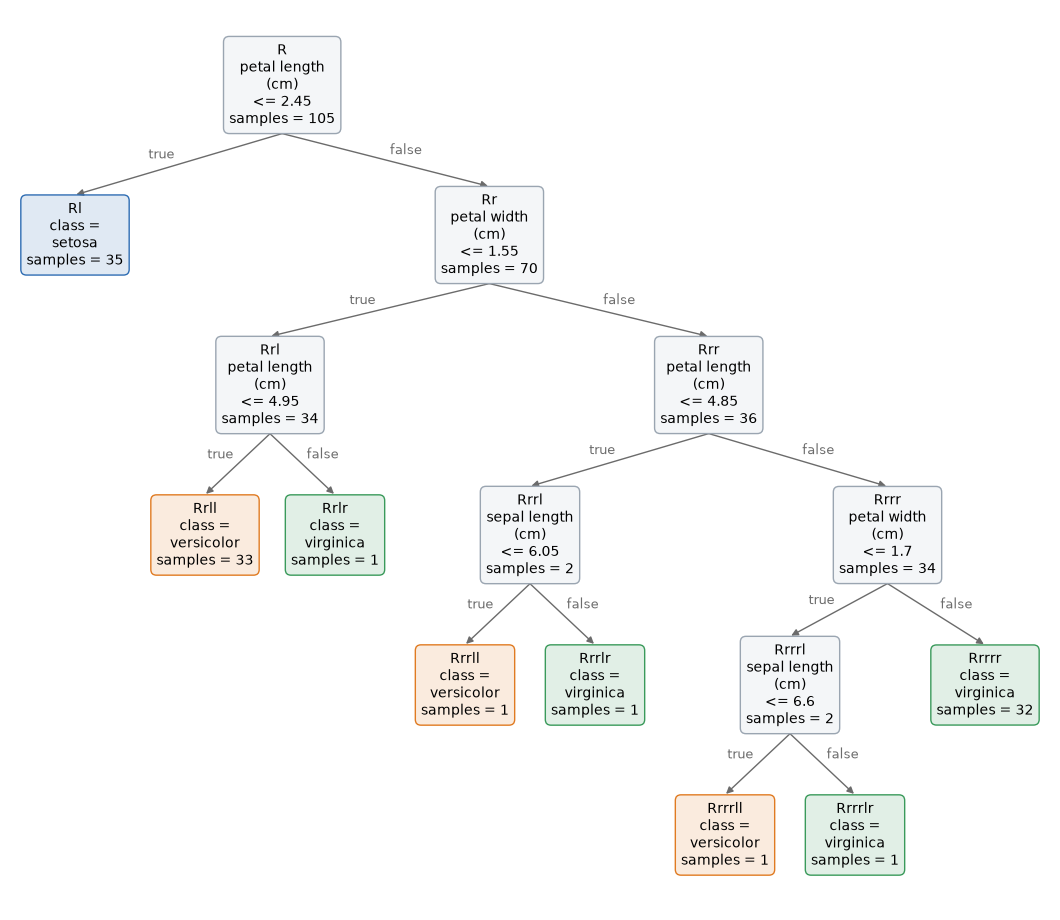

In [6]:
import matplotlib.pyplot as plt

# wrap: at most 12 characters per line, for the long names of the features
rt.plot_tree(columns_names=list(df.columns[:-1]), wrap=12)
plt.show()